In [17]:
# ---- Setup: Drive + code + wandb (run this first, every session) ----
REPO_URL = "https://github.com/YOUR_USERNAME/YOUR_REPO.git"   # <-- EDIT ONCE
BRANCH = "main"

import os, subprocess, sys
from google.colab import drive, userdata

# Drive must be mounted from the notebook kernel (never from a !python subprocess).
drive.mount("/content/drive")

# Code: fresh clone each session (Colab disk is wiped on reset), pull if it already exists.
# For a private repo, add a Colab secret GITHUB_TOKEN (a fine-grained read-only token).
CODE = "/content/fyp"
url = REPO_URL
try:
    tok = userdata.get("GITHUB_TOKEN")
    url = REPO_URL.replace("https://", f"https://{tok}@")
except Exception:
    pass
if os.path.isdir(CODE):
    subprocess.run(["git", "-C", CODE, "pull", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", "-b", BRANCH, url, CODE], check=True)
print(subprocess.check_output(["git", "-C", CODE, "log", "-1", "--oneline"]).decode())

# Dependencies (torch/torchvision come preinstalled with Colab's CUDA build; don't reinstall them).
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{CODE}/requirements.txt"], check=True)

# wandb: key comes from the Colab secret WANDB_API_KEY (key icon in the left sidebar). Never hardcode it.
import wandb
wandb.login(key=userdata.get("WANDB_API_KEY"))

sys.path.insert(0, f"{CODE}/src")
# Python caches imported modules for the whole kernel session, so after a git pull
# a plain `import` would silently keep running the OLD code. Drop the cached copies.
for _m in ["fyp_infra", "stage1_runner"]:
    sys.modules.pop(_m, None)
import torch
from fyp_infra import setup_paths, run_sweep, run_id, load_result
import stage1_runner as sr
paths = setup_paths()   # -> /content/drive/MyDrive/fyp_nested_cl/{data,results,logs}
print(paths)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch runtime to GPU!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
dc20c7c stage 0 fixes



wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


{'root': '/content/drive/MyDrive/fyp_nested_cl', 'data': '/content/drive/MyDrive/fyp_nested_cl/data', 'results': '/content/drive/MyDrive/fyp_nested_cl/results', 'logs': '/content/drive/MyDrive/fyp_nested_cl/logs'}
GPU: Tesla T4


In [5]:
#download cifar100 dataset to drive once

from torchvision.datasets import CIFAR100
CIFAR100(paths["data"], train=True, download=True); CIFAR100(paths["data"], train=False, download=True)
print(os.listdir(paths["data"]))

100%|██████████| 169M/169M [27:48<00:00, 101kB/s]


['cifar-100-python.tar.gz', 'cifar-100-python']


In [6]:
#gpu smoke test

cfg = sr.make_cfg(stage="smoke", n_experiences=2, epochs=1)
out = run_sweep([cfg], sr.run_experiment, paths, force=True)
print(out[run_id(cfg)]["metrics"]["acc_matrix"])

[1/1] be588cd1e5d7 running


/usr/local/lib/python3.13/dist-packages/avalanche/training/plugins/evaluation.py:94: UserWarning: No loggers specified, metrics will not be logged
  warnings.warn("No loggers specified, metrics will not be logged")


  exp 1/2: seen-avg 14.54%  current 14.54%
  exp 2/2: seen-avg 11.11%  current 22.22%


acc_current_exp,▁█
acc_exp/00,█▁
acc_exp/01,▁
acc_seen_avg,█▁
exp,▁█
optimizer_steps,▁█
acc_current_exp,22.22
acc_exp/00,0
acc_exp/01,22.22
acc_seen_avg,11.11
avg_forgetting,14.54


[[14.540000000000001, 0.0], [0.0, 22.220000000000002]]


**Stage 0:**

In [18]:
EPOCHS = 1           # Gate 0 only needs the pipeline to work; real epochs come from the Stage 1 sweep
CONFIGS = [sr.make_cfg(stage="stage0", strategy="ewc", ewc_lambda=1.0, epochs=EPOCHS, seed=s)
           for s in (0, 1)]
SHOW = ["strategy", "seed", "epochs", "n_experiences"]
for c in CONFIGS: print(run_id(c), {k: c[k] for k in SHOW})

1761e09d8d0a {'strategy': 'ewc', 'seed': 0, 'epochs': 1, 'n_experiences': 20}
c8773404d9fb {'strategy': 'ewc', 'seed': 1, 'epochs': 1, 'n_experiences': 20}


In [19]:
out = run_sweep(CONFIGS, sr.run_experiment, paths)

[1/2] 1761e09d8d0a running


/usr/local/lib/python3.13/dist-packages/avalanche/training/plugins/evaluation.py:94: UserWarning: No loggers specified, metrics will not be logged
  warnings.warn("No loggers specified, metrics will not be logged")


  exp 1/20: seen-avg 42.20%  current 42.20%  train-loss 2.810
  exp 2/20: seen-avg 34.50%  current 69.00%  train-loss 2.552
  exp 3/20: seen-avg 14.40%  current 43.20%  train-loss 3.241
  exp 4/20: seen-avg 15.80%  current 63.20%  train-loss 2.934
  exp 5/20: seen-avg 9.04%  current 45.20%  train-loss 3.432
  exp 6/20: seen-avg 7.77%  current 46.60%  train-loss 3.228
  exp 7/20: seen-avg 8.74%  current 61.20%  train-loss 3.133
  exp 8/20: seen-avg 6.98%  current 55.80%  train-loss 3.333
  exp 9/20: seen-avg 5.22%  current 47.00%  train-loss 3.674
  exp 10/20: seen-avg 5.96%  current 59.60%  train-loss 3.489
  exp 11/20: seen-avg 5.18%  current 57.00%  train-loss 3.569
  exp 12/20: seen-avg 4.12%  current 49.40%  train-loss 3.778
  exp 13/20: seen-avg 3.55%  current 46.20%  train-loss 4.043
  exp 14/20: seen-avg 4.06%  current 56.80%  train-loss 3.840
  exp 15/20: seen-avg 3.32%  current 49.80%  train-loss 4.146
  exp 16/20: seen-avg 3.74%  current 59.80%  train-loss 3.765
  exp 17/20: 

acc_current_exp,▁█▁▆▂▂▆▅▂▆▅▃▂▅▃▆█▄▄▄
acc_exp/00,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/01,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/02,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/03,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/04,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/05,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/06,█▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/07,█▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/08,█▁▁▁▁▁▁▁▁▁▁▁
+15,...


[2/2] c8773404d9fb running


/usr/local/lib/python3.13/dist-packages/avalanche/training/plugins/evaluation.py:94: UserWarning: No loggers specified, metrics will not be logged
  warnings.warn("No loggers specified, metrics will not be logged")


  exp 1/20: seen-avg 35.80%  current 35.80%  train-loss 2.795
  exp 2/20: seen-avg 24.10%  current 48.20%  train-loss 2.976
  exp 3/20: seen-avg 17.60%  current 52.80%  train-loss 2.801
  exp 4/20: seen-avg 14.35%  current 57.40%  train-loss 3.135
  exp 5/20: seen-avg 10.44%  current 52.20%  train-loss 3.399
  exp 6/20: seen-avg 10.63%  current 63.80%  train-loss 3.131
  exp 7/20: seen-avg 9.46%  current 66.20%  train-loss 3.149
  exp 8/20: seen-avg 6.83%  current 54.60%  train-loss 3.379
  exp 9/20: seen-avg 6.02%  current 54.20%  train-loss 3.329
  exp 10/20: seen-avg 5.34%  current 53.40%  train-loss 3.527
  exp 11/20: seen-avg 4.29%  current 47.20%  train-loss 3.554
  exp 12/20: seen-avg 4.58%  current 55.00%  train-loss 3.511
  exp 13/20: seen-avg 4.34%  current 56.40%  train-loss 3.579
  exp 14/20: seen-avg 3.61%  current 50.60%  train-loss 3.977
  exp 15/20: seen-avg 4.04%  current 60.60%  train-loss 3.783
  exp 16/20: seen-avg 2.88%  current 46.00%  train-loss 4.389
  exp 17/20

acc_current_exp,▁▄▅▆▅▇█▅▅▅▄▅▆▄▇▃▆▄▅▇
acc_exp/00,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/01,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/02,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/03,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/04,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/05,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/06,█▁▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/07,█▁▁▁▁▁▁▁▁▁▁▁▁
acc_exp/08,█▁▁▁▁▁▁▁▁▁▁▁
+15,...


In [20]:
import numpy as np, pandas as pd
rows = []
for cfg in CONFIGS:
    r = load_result(cfg, paths)
    if r is None:
        rows.append({**{k: cfg[k] for k in SHOW}, "status": "not finished"}); continue
    m = r["metrics"]
    rows.append({**{k: cfg[k] for k in SHOW}, "run_id": r["run_id"],
                 "final_avg_acc": m["final_avg_acc"], "avg_forgetting": m["avg_forgetting"],
                 "avg_incremental_acc": m["avg_incremental_acc"],
                 "steps": m["optimizer_steps"], "n_params": m["n_params"], "minutes": r["wall_clock_s"] / 60})
df = pd.DataFrame(rows); df

,strategy,seed,epochs,n_experiences,run_id,final_avg_acc,avg_forgetting,avg_incremental_acc,steps,n_params,minutes
0,ewc,0,1,20,1761e09d8d0a,2.65,53.936842,9.349610,1580,1109240,7.017677
1,ewc,1,1,20,c8773404d9fb,3.14,53.421053,8.819789,1580,1109240,7.127824


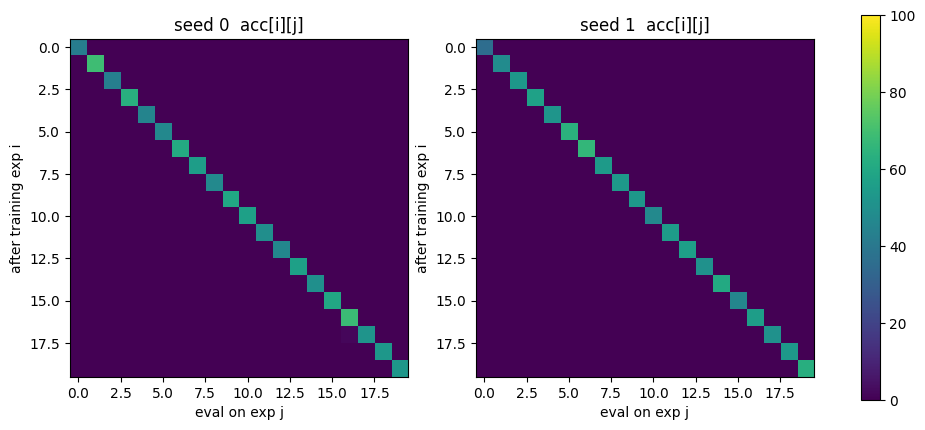

In [21]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(CONFIGS), figsize=(6 * len(CONFIGS), 5))
for ax, cfg in zip(np.atleast_1d(axes), CONFIGS):
    r = load_result(cfg, paths)
    if r is None: continue
    im = ax.imshow(np.array(r["metrics"]["acc_matrix"]), vmin=0, vmax=100, cmap="viridis")
    ax.set(title=f"seed {cfg['seed']}  acc[i][j]", xlabel="eval on exp j", ylabel="after training exp i")
fig.colorbar(im, ax=axes); plt.show()